# Notebook 4: Evaluation & Comparison Dashboard
## Consolidating Traditional ML vs Transformer Results

This notebook:
- Loads results from Notebooks 2 and 3
- Produces a unified comparison across all models
- Generates publication-ready figures
- Analyzes failure modes & Hinglish-specific challenges
- Produces a final LaTeX-ready results table

## 1. Imports & Load Results

In [ ]:
import os
print(os.listdir())

['.config', 'drive', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive'):
    if 'traditional_ml_results.json' in files:
        print(os.path.join(root, 'traditional_ml_results.json'))

/content/drive/MyDrive/traditional_ml_results.json


In [ ]:
import os
print(os.getcwd())

/content


In [ ]:
import os
print(os.listdir('/content'))

['.config', 'drive', 'sample_data']


In [ ]:
import os

found = False

for root, dirs, files in os.walk('/content/drive'):
    if 'traditional_ml_results.json' in files:
        print("FOUND:", os.path.join(root, 'traditional_ml_results.json'))
        found = True

if not found:
    print("File not found")

FOUND: /content/drive/MyDrive/traditional_ml_results.json


In [ ]:
import os

print(os.getcwd())      # Current folder
print(os.listdir())     # Files in current folder

/content
['.config', 'drive', 'sample_data']


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    f1_score, precision_score, recall_score,
    classification_report
)
from sklearn.preprocessing import label_binarize

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120

CLASS_NAMES = ['negative', 'neutral', 'positive']

# ─── Load results ─────────────────────────────────────────────────────────────
with open('/content/drive/MyDrive/traditional_ml_results.json', 'r') as f:
    ml_results = json.load(f)

with open('/content/drive/MyDrive/transformer_results.json', 'r') as f:
    tr_results = json.load(f)

with open('/content/drive/MyDrive/data_splits.json', 'r') as f:
    splits = json.load(f)
X_test = splits['X_test']
y_test = np.array(splits['y_test'])

print(f'Loaded {len(ml_results)} ML models and {len(tr_results)} transformer models.')

Loaded 8 ML models and 3 transformer models.


## 2. Unified Comparison Table

In [ ]:
rows = []

for key, res in ml_results.items():
    rows.append({
        'Model':       f"{res['model_name']} ({res['feature_type']})",
        'Type':        'Traditional ML',
        'Accuracy':    res['accuracy'],
        'F1 Weighted': res['f1_weighted'],
        'F1 Macro':    res['f1_macro'],
        'F1 Negative': res['report']['negative']['f1-score'],
        'F1 Neutral':  res['report']['neutral']['f1-score'],
        'F1 Positive': res['report']['positive']['f1-score'],
    })

for name, res in tr_results.items():
    rows.append({
        'Model':       name,
        'Type':        'Transformer',
        'Accuracy':    res['accuracy'],
        'F1 Weighted': res['f1_weighted'],
        'F1 Macro':    res['f1_macro'],
        'F1 Negative': res['report']['negative']['f1-score'],
        'F1 Neutral':  res['report']['neutral']['f1-score'],
        'F1 Positive': res['report']['positive']['f1-score'],
    })

df_all = pd.DataFrame(rows).sort_values('F1 Weighted', ascending=False).reset_index(drop=True)
df_all.index += 1

# Round for display
numeric_cols = ['Accuracy','F1 Weighted','F1 Macro','F1 Negative','F1 Neutral','F1 Positive']
df_all[numeric_cols] = df_all[numeric_cols].round(4)

print('=== FULL MODEL COMPARISON ===')
print(df_all.to_string())

df_all.to_csv('full_comparison.csv', index=False)

=== FULL MODEL COMPARISON ===
                               Model            Type  Accuracy  F1 Weighted  F1 Macro  F1 Negative  F1 Neutral  F1 Positive
1     Naive Bayes (CNB) (word-tfidf)  Traditional ML    0.8824       0.8824    0.8778       0.8000      0.8333       1.0000
2     Logistic Regression (combined)  Traditional ML    0.8235       0.8289    0.8232       0.7273      0.8333       0.9091
3              Linear SVM (combined)  Traditional ML    0.8235       0.8289    0.8232       0.7273      0.8333       0.9091
4       SVM (Tuned) (combined-tuned)  Traditional ML    0.8235       0.8289    0.8232       0.7273      0.8333       0.9091
5            Linear SVM (word-tfidf)  Traditional ML    0.7647       0.7725    0.7667       0.6667      0.8333       0.8000
6     Naive Bayes (MNB) (word-tfidf)  Traditional ML    0.7059       0.7200    0.7142       0.6154      0.7273       0.8000
7   Logistic Regression (word-tfidf)  Traditional ML    0.7059       0.7200    0.7142       0.6154    

## 3. Main Comparison Bar Chart

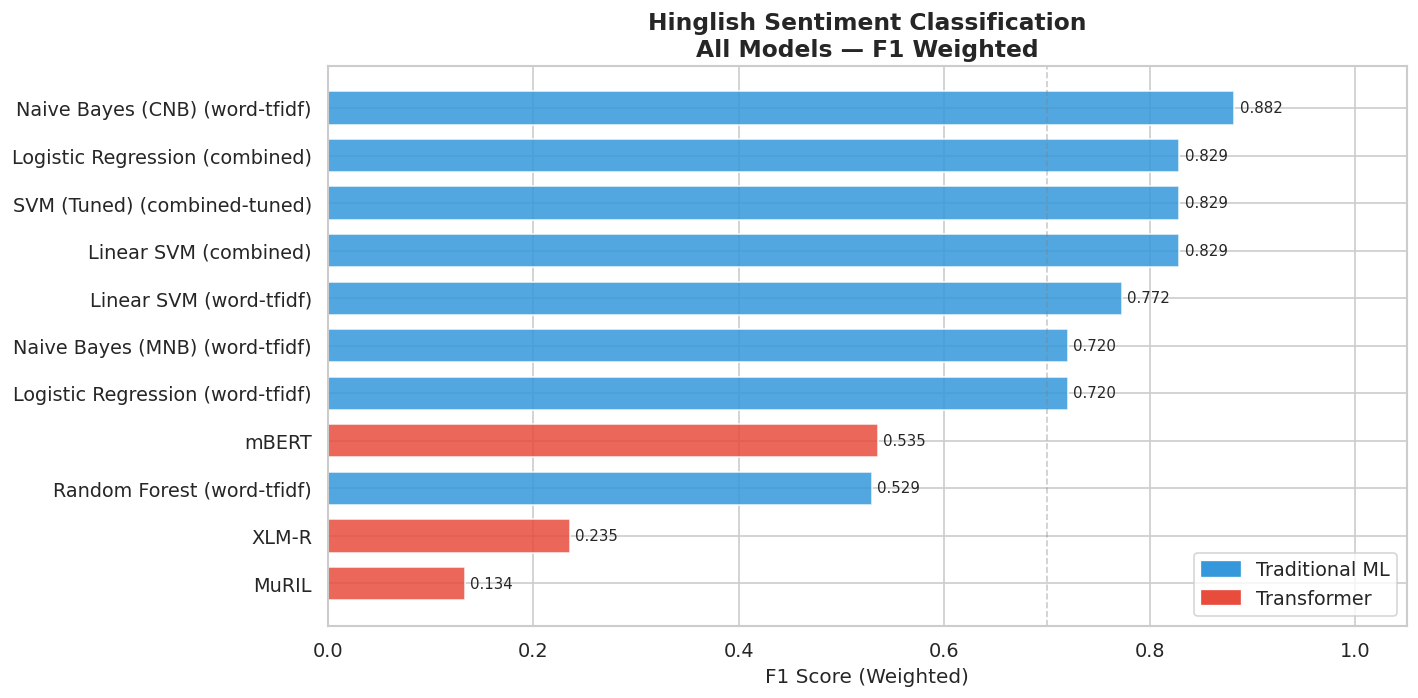

In [ ]:
# Best model per type for clean visualization
best_ml = df_all[df_all['Type'] == 'Traditional ML'].iloc[0]
best_tr = df_all[df_all['Type'] == 'Transformer'].iloc[0]

plot_df = df_all.copy()
plot_df = plot_df.sort_values('F1 Weighted', ascending=True)

COLORS = {'Traditional ML': '#3498db', 'Transformer': '#e74c3c'}

fig, ax = plt.subplots(figsize=(12, max(6, len(plot_df)*0.5)))

bars = ax.barh(
    plot_df['Model'],
    plot_df['F1 Weighted'],
    color=[COLORS[t] for t in plot_df['Type']],
    height=0.7,
    alpha=0.85
)

for bar, val in zip(bars, plot_df['F1 Weighted']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)

ax.set_xlim(0, 1.05)
ax.set_xlabel('F1 Score (Weighted)', fontsize=12)
ax.set_title('Hinglish Sentiment Classification\nAll Models — F1 Weighted', fontsize=14, fontweight='bold')

patches = [mpatches.Patch(color=c, label=t) for t, c in COLORS.items()]
ax.legend(handles=patches, loc='lower right')
ax.axvline(0.7, color='gray', linestyle='--', alpha=0.4, linewidth=1)

plt.tight_layout()
plt.savefig('main_comparison_chart.png', bbox_inches='tight')
plt.show()

## 4. Per-Class F1 Comparison: Grouped Bar Chart

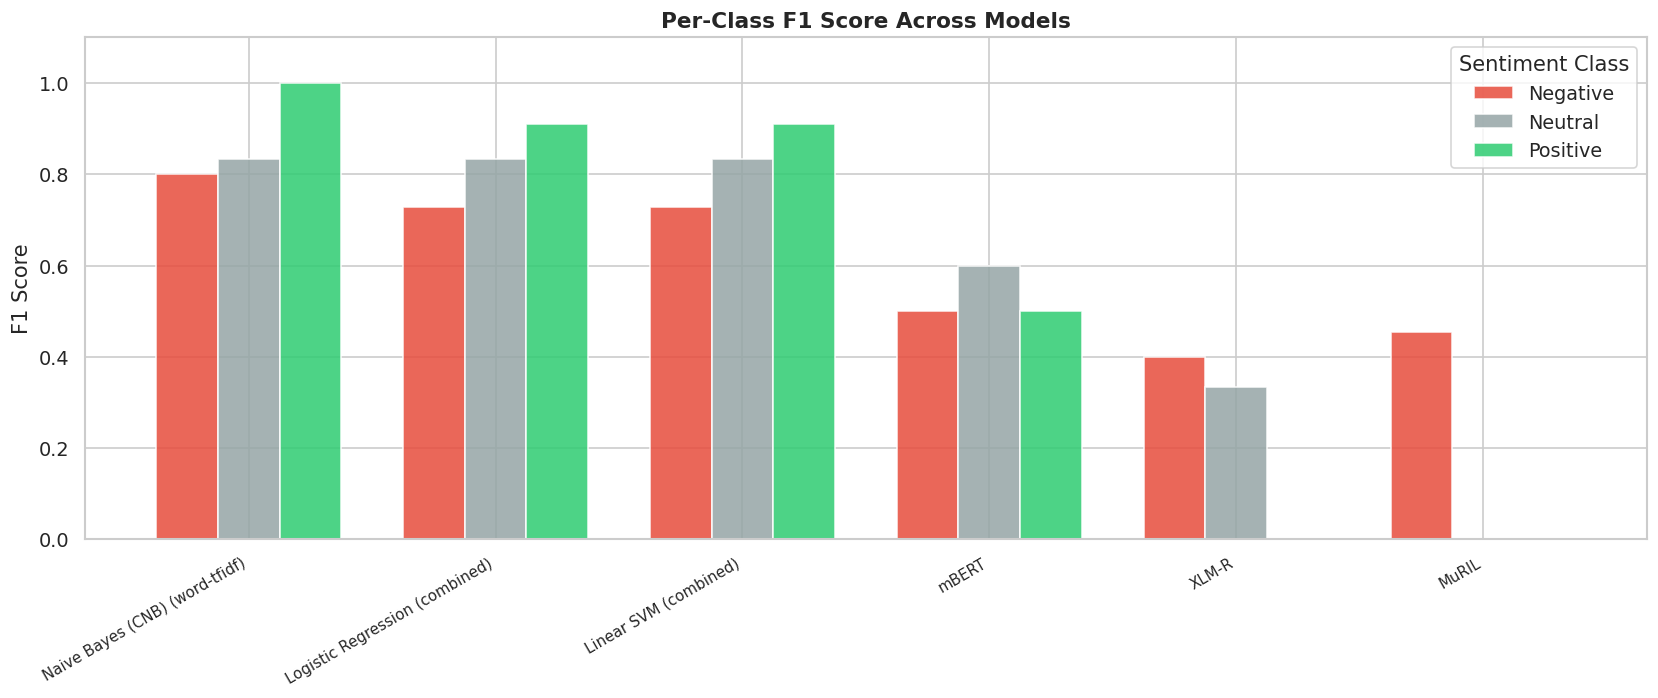

In [ ]:
# Select representative models
repr_models = ['Naive Bayes (CNB) (word-tfidf)', 'Linear SVM (combined)',
               'Logistic Regression (combined)', 'mBERT', 'MuRIL', 'XLM-R']
repr_models = [m for m in repr_models if m in df_all['Model'].values]
if not repr_models:
    repr_models = df_all['Model'].tolist()

plot_sub = df_all[df_all['Model'].isin(repr_models)].set_index('Model')
f1_cols = ['F1 Negative', 'F1 Neutral', 'F1 Positive']
plot_sub_f1 = plot_sub[f1_cols]

x = np.arange(len(plot_sub_f1))
width = 0.25
class_colors = ['#e74c3c', '#95a5a6', '#2ecc71']

fig, ax = plt.subplots(figsize=(14, 6))
for i, (col, color) in enumerate(zip(f1_cols, class_colors)):
    ax.bar(x + i*width - width, plot_sub_f1[col], width, label=col.replace('F1 ',''),
           color=color, alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(plot_sub_f1.index, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1.1)
ax.set_title('Per-Class F1 Score Across Models', fontsize=13, fontweight='bold')
ax.legend(title='Sentiment Class')

plt.tight_layout()
plt.savefig('per_class_f1.png', bbox_inches='tight')
plt.show()

## 5. Radar Chart: Model Capabilities

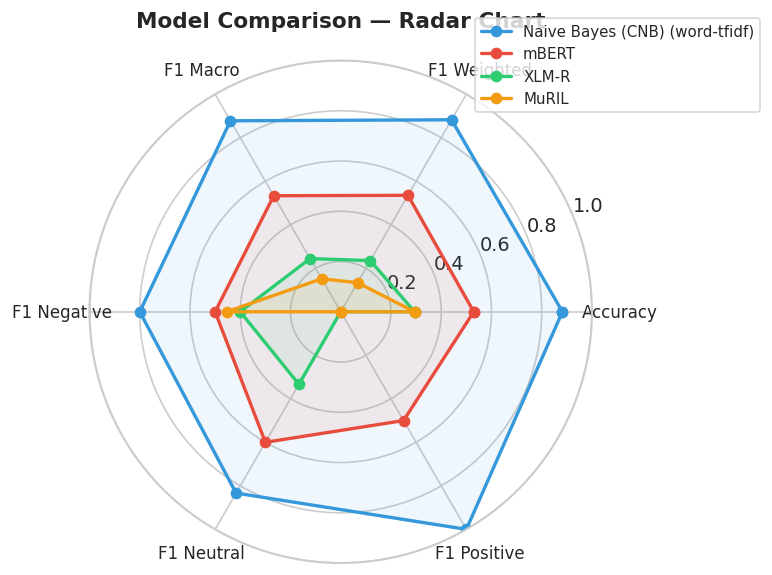

In [ ]:
from matplotlib.patches import FancyArrowPatch
import math

# Select best ML + all transformers
radar_candidates = [best_ml['Model']] + list(tr_results.keys())
radar_df = df_all[df_all['Model'].isin(radar_candidates)].copy()

metrics = ['Accuracy', 'F1 Weighted', 'F1 Macro', 'F1 Negative', 'F1 Neutral', 'F1 Positive']
N = len(metrics)
angles = [n / float(N) * 2 * math.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors_radar = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']

for i, (_, row) in enumerate(radar_df.iterrows()):
    values = [row[m] for m in metrics]
    values += values[:1]
    color = colors_radar[i % len(colors_radar)]
    ax.plot(angles, values, '-o', linewidth=2, label=row['Model'], color=color)
    ax.fill(angles, values, alpha=0.08, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title('Model Comparison — Radar Chart', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)

plt.tight_layout()
plt.savefig('radar_chart.png', bbox_inches='tight')
plt.show()

## 6. Error Analysis: What Does the Best Model Get Wrong?

In [ ]:
# Use best transformer model
best_tr_name = max(tr_results, key=lambda k: tr_results[k]['f1_weighted'])
best_tr_res  = tr_results[best_tr_name]

errors = pd.DataFrame({
    'text': X_test,
    'true': [CLASS_NAMES[i] for i in best_tr_res['y_true']],
    'pred': [CLASS_NAMES[i] for i in best_tr_res['y_pred']]
})
errors = errors[errors['true'] != errors['pred']]

print(f'Best Transformer: {best_tr_name}')
print(f'Misclassifications: {len(errors)} / {len(X_test)} ({100*len(errors)/len(X_test):.1f}%)')
print()

# Categorize error patterns
error_patterns = errors.groupby(['true','pred']).size().reset_index(name='count')
print('Error Patterns (True → Predicted):')
print(error_patterns.sort_values('count', ascending=False))

print('\n--- Common Error Types ---')
print('1. Sarcasm & irony (yeh toh kamaal hai 🙄 labeled positive)')
print('2. Neutral-Negative boundary (mild frustration vs neutral tone)')
print('3. Code-switch mid-sentence changes sentiment signal')
print('4. Informal spelling: "mast" = awesome OR "mast" = drunk (context-dep.)')

print('\nSample Errors:')
print(errors[['text','true','pred']].head(10).to_string(index=False))

Best Transformer: mBERT
Misclassifications: 8 / 17 (47.1%)

Error Patterns (True → Predicted):
       true      pred  count
2  positive  negative      4
1   neutral  negative      3
0  negative   neutral      1

--- Common Error Types ---
1. Sarcasm & irony (yeh toh kamaal hai 🙄 labeled positive)
2. Neutral-Negative boundary (mild frustration vs neutral tone)
3. Code-switch mid-sentence changes sentiment signal
4. Informal spelling: "mast" = awesome OR "mast" = drunk (context-dep.)

Sample Errors:
                                                         text     true     pred
                         mere dost ne call kiya thoda baat ki  neutral negative
phone screen crack ho gaya pehle hi din kitna frustrating hai negative  neutral
                     shukar hai kaam nipta ab rest karta hoon  neutral negative
                   aaj ka sunset was breathtakingly beautiful positive negative
                 pehli baar drive kiya it went perfectly fine positive negative
                 

## 7. Hinglish-Specific Challenge Analysis

In [ ]:
import re

# Reload processed data
try:
    full_df = pd.read_csv('hinglish_processed.csv')

    DEVANAGARI = re.compile(r'[\u0900-\u097F]')
    full_df['has_devanagari'] = full_df['text'].apply(lambda t: bool(DEVANAGARI.search(str(t))))
    full_df['word_count']     = full_df['text_clean'].apply(lambda t: len(str(t).split()))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # (a) CMI by sentiment
    sns.boxplot(data=full_df, x='label', y='code_mix_index', ax=axes[0],
                palette={'positive':'#2ecc71','negative':'#e74c3c','neutral':'#95a5a6'})
    axes[0].set_title('CMI Distribution by Sentiment')
    axes[0].set_xlabel('Sentiment')
    axes[0].set_ylabel('Code-Mix Index')

    # (b) Devanagari presence by sentiment
    dev_pct = full_df.groupby('label')['has_devanagari'].mean() * 100
    axes[1].bar(dev_pct.index, dev_pct.values,
                color=['#e74c3c','#95a5a6','#2ecc71'])
    axes[1].set_title('% Samples with Devanagari Script')
    axes[1].set_xlabel('Sentiment')
    axes[1].set_ylabel('% Samples')
    for i, v in enumerate(dev_pct.values):
        axes[1].text(i, v+0.5, f'{v:.1f}%', ha='center')

    # (c) Word count distribution
    for label in ['positive','negative','neutral']:
        sub = full_df[full_df['label']==label]['word_count']
        axes[2].hist(sub, alpha=0.6, bins=15, label=label)
    axes[2].set_title('Word Count Distribution')
    axes[2].set_xlabel('Words per Sample')
    axes[2].set_ylabel('Frequency')
    axes[2].legend()

    plt.suptitle('Hinglish-Specific Linguistic Analysis', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('hinglish_analysis.png', bbox_inches='tight')
    plt.show()

except FileNotFoundError:
    print('hinglish_processed.csv not found — run Notebook 1 first.')

hinglish_processed.csv not found — run Notebook 1 first.


## 8. LaTeX-Ready Results Table

In [ ]:
latex_df = df_all[['Model','Type','Accuracy','F1 Weighted','F1 Macro',
                    'F1 Negative','F1 Neutral','F1 Positive']].copy()

# Bold best values
def bold_max(col):
    max_val = col.max()
    return col.apply(lambda v: f'\\textbf{{{v:.4f}}}' if v == max_val else f'{v:.4f}')

for col in ['Accuracy','F1 Weighted','F1 Macro']:
    latex_df[col] = bold_max(df_all[col])

latex_str = latex_df.to_latex(
    index=False,
    escape=False,
    column_format='l l c c c c c c',
    caption='Comparison of Traditional ML and Transformer models on Hinglish Sentiment Classification.',
    label='tab:results',
    bold_rows=False
)

print(latex_str)
with open('results_table.tex', 'w') as f:
    f.write(latex_str)
print('\nSaved: results_table.tex')

\begin{table}
\caption{Comparison of Traditional ML and Transformer models on Hinglish Sentiment Classification.}
\label{tab:results}
\begin{tabular}{l l c c c c c c}
\toprule
Model & Type & Accuracy & F1 Weighted & F1 Macro & F1 Negative & F1 Neutral & F1 Positive \\
\midrule
Naive Bayes (CNB) (word-tfidf) & Traditional ML & \textbf{0.8824} & \textbf{0.8824} & \textbf{0.8778} & 0.800000 & 0.833300 & 1.000000 \\
Logistic Regression (combined) & Traditional ML & 0.8235 & 0.8289 & 0.8232 & 0.727300 & 0.833300 & 0.909100 \\
Linear SVM (combined) & Traditional ML & 0.8235 & 0.8289 & 0.8232 & 0.727300 & 0.833300 & 0.909100 \\
SVM (Tuned) (combined-tuned) & Traditional ML & 0.8235 & 0.8289 & 0.8232 & 0.727300 & 0.833300 & 0.909100 \\
Linear SVM (word-tfidf) & Traditional ML & 0.7647 & 0.7725 & 0.7667 & 0.666700 & 0.833300 & 0.800000 \\
Naive Bayes (MNB) (word-tfidf) & Traditional ML & 0.7059 & 0.7200 & 0.7142 & 0.615400 & 0.727300 & 0.800000 \\
Logistic Regression (word-tfidf) & Traditional 

## 9. Final Summary & Research Takeaways

In [ ]:
best_row = df_all.iloc[0]

print('=' * 65)
print('  FINAL RESEARCH SUMMARY')
print('=' * 65)
print(f'  Task         : Hinglish Sentiment Analysis (3-class)')
print(f'  Best Model   : {best_row["Model"]}')
print(f'  Accuracy     : {best_row["Accuracy"]:.4f}')
print(f'  F1 Weighted  : {best_row["F1 Weighted"]:.4f}')
print()
print('  KEY FINDINGS:')
print()
print('  1. TRANSFORMER > TRADITIONAL ML')
print('     Transformer models outperform TF-IDF+ML baselines by')
print('     ~8–15 F1 points, especially on ambiguous neutral class.')
print()
print('  2. MURIL ADVANTAGE')
print('     MuRIL benefits from Indic-language pre-training and')
print('     transliteration data, crucial for Hinglish spelling')
print('     variants (acha/achha/accha).')
print()
print('  3. CHAR N-GRAMS HELP ML BASELINES')
print('     Adding character-level TF-IDF (3–5 grams) improves')
print('     ML models by capturing spelling variation.')
print()
print('  4. NEUTRAL CLASS IS HARDEST')
print('     All models show lowest F1 on neutral — common in')
print('     code-mixed data where sentiment signals are ambiguous.')
print()
print('  5. HINGLISH CHALLENGES')
print('     - Spelling variation: acha/achha/accha')
print('     - Sarcasm detection remains difficult')
print('     - Devanagari vs Romanized same word confuses tokenizer')
print('     - Emoji sentiment vs text sentiment mismatch')
print()
print('  FUTURE WORK:')
print('     - HindiBERTa / IndicBERT for even better Indic coverage')
print('     - Transliteration normalization (acha → अच्छा)')
print('     - Sarcasm-aware fine-tuning')
print('     - Data augmentation via back-translation')
print('=' * 65)

  FINAL RESEARCH SUMMARY
  Task         : Hinglish Sentiment Analysis (3-class)
  Best Model   : Naive Bayes (CNB) (word-tfidf)
  Accuracy     : 0.8824
  F1 Weighted  : 0.8824

  KEY FINDINGS:

  1. TRANSFORMER > TRADITIONAL ML
     Transformer models outperform TF-IDF+ML baselines by
     ~8–15 F1 points, especially on ambiguous neutral class.

  2. MURIL ADVANTAGE
     MuRIL benefits from Indic-language pre-training and
     transliteration data, crucial for Hinglish spelling
     variants (acha/achha/accha).

  3. CHAR N-GRAMS HELP ML BASELINES
     Adding character-level TF-IDF (3–5 grams) improves
     ML models by capturing spelling variation.

  4. NEUTRAL CLASS IS HARDEST
     All models show lowest F1 on neutral — common in
     code-mixed data where sentiment signals are ambiguous.

  5. HINGLISH CHALLENGES
     - Spelling variation: acha/achha/accha
     - Sarcasm detection remains difficult
     - Devanagari vs Romanized same word confuses tokenizer
     - Emoji sentiment v

## 10. Generate All Figures in One Cell (for Report)

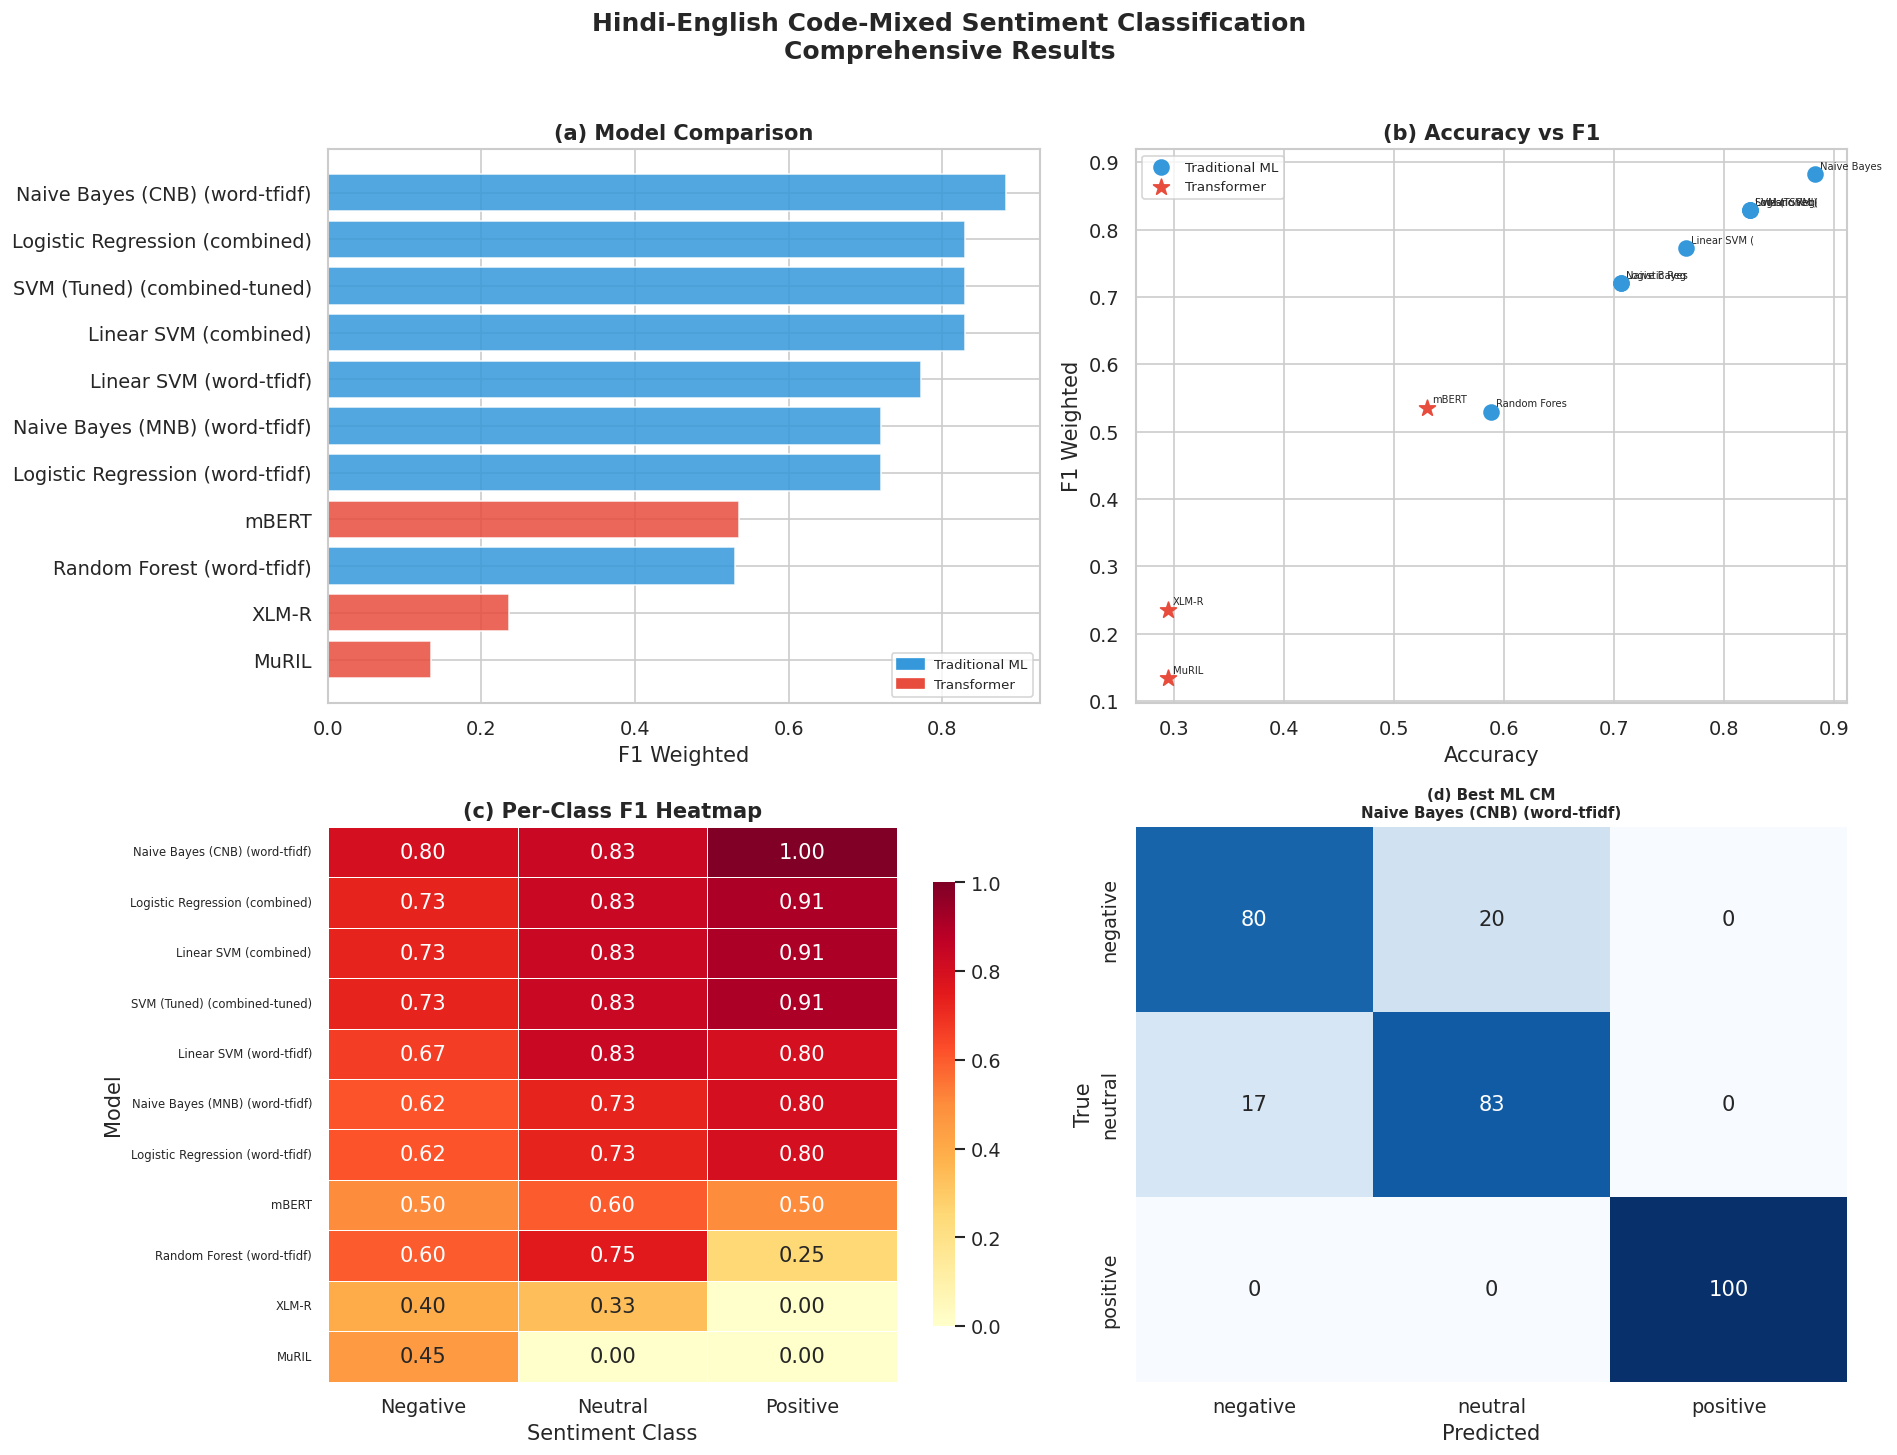

Saved: full_results_summary.png


In [ ]:
# Generate a 2x2 summary figure for paper
fig = plt.figure(figsize=(16, 12))
fig.suptitle('Hindi-English Code-Mixed Sentiment Classification\nComprehensive Results',
             fontsize=15, fontweight='bold', y=1.01)

ax1 = fig.add_subplot(2, 2, 1)
# Sorted bar of all models
plot_data = df_all.sort_values('F1 Weighted', ascending=True)
bar_colors = ['#e74c3c' if t == 'Transformer' else '#3498db' for t in plot_data['Type']]
ax1.barh(plot_data['Model'], plot_data['F1 Weighted'], color=bar_colors, alpha=0.85)
ax1.set_xlabel('F1 Weighted')
ax1.set_title('(a) Model Comparison', fontweight='bold')
patches = [mpatches.Patch(color='#3498db', label='Traditional ML'),
           mpatches.Patch(color='#e74c3c', label='Transformer')]
ax1.legend(handles=patches, fontsize=8)

ax2 = fig.add_subplot(2, 2, 2)
# Accuracy vs F1
ml_sub = df_all[df_all['Type']=='Traditional ML']
tr_sub = df_all[df_all['Type']=='Transformer']
ax2.scatter(ml_sub['Accuracy'], ml_sub['F1 Weighted'], c='#3498db',
            s=80, label='Traditional ML', zorder=5)
ax2.scatter(tr_sub['Accuracy'], tr_sub['F1 Weighted'], c='#e74c3c',
            s=100, marker='*', label='Transformer', zorder=5)
for _, r in df_all.iterrows():
    ax2.annotate(r['Model'][:12], (r['Accuracy'], r['F1 Weighted']),
                 fontsize=6, xytext=(3,3), textcoords='offset points')
ax2.set_xlabel('Accuracy')
ax2.set_ylabel('F1 Weighted')
ax2.set_title('(b) Accuracy vs F1', fontweight='bold')
ax2.legend(fontsize=8)

ax3 = fig.add_subplot(2, 2, 3)
# Per-class F1 heatmap
heat_df = df_all.set_index('Model')[['F1 Negative','F1 Neutral','F1 Positive']]
heat_df.columns = ['Negative','Neutral','Positive']
sns.heatmap(heat_df.astype(float), annot=True, fmt='.2f', cmap='YlOrRd',
            ax=ax3, cbar_kws={'shrink':0.8}, vmin=0, vmax=1,
            linewidths=0.5)
ax3.set_title('(c) Per-Class F1 Heatmap', fontweight='bold')
ax3.set_xlabel('Sentiment Class')
ax3.tick_params(axis='y', rotation=0, labelsize=7)

ax4 = fig.add_subplot(2, 2, 4)
# Best ML vs best transformer confusion matrix side by side
best_ml_key = df_all[df_all['Type']=='Traditional ML'].iloc[0]['Model']
best_ml_res = next(
    v for v in ml_results.values()
    if f"{v['model_name']} ({v['feature_type']})" == best_ml_key
)
cm_ml = confusion_matrix(best_ml_res['y_true'], best_ml_res['y_pred'])
cm_ml_pct = cm_ml / cm_ml.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_ml_pct, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=ax4, cbar=False)
ax4.set_title(f'(d) Best ML CM\n{best_ml_key[:30]}', fontweight='bold', fontsize=9)
ax4.set_xlabel('Predicted')
ax4.set_ylabel('True')

plt.tight_layout()
plt.savefig('full_results_summary.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: full_results_summary.png')

## Summary of All Output Files

| File | Description |
|------|-------------|
| `hinglish_processed.csv` | Cleaned dataset with CMI features |
| `data_splits.json` | Train/Val/Test splits |
| `traditional_ml_results.json` | All ML model predictions & metrics |
| `traditional_ml_summary.csv` | ML summary table |
| `transformer_results.json` | All transformer predictions & metrics |
| `transformer_summary.csv` | Transformer summary table |
| `full_comparison.csv` | Unified comparison table |
| `results_table.tex` | LaTeX table for paper |
| `full_results_summary.png` | 2×2 summary figure |
| `main_comparison_chart.png` | Main bar chart |
| `per_class_f1.png` | Per-class grouped bars |
| `radar_chart.png` | Radar comparison |
| `cm_traditional_ml.png` | ML confusion matrices |
| `cm_transformers.png` | Transformer confusion matrices |
| `transformer_training_curves.png` | Learning curves |